# Study NNN: <title>  (replication notebook)

**Question.** <one sentence: what does this study test, and why does it matter for compounded net return (CLAUDE.md G1/G2)?>

| Field | Entry |
|---|---|
| Study | `research/NNN_<slug>/` |
| PREREG commit | `<sha>` (pre-registered before any result existed) |
| Verdict | <promote / park / kill, or "pending" until RESULT.md is written> |
| Entry point | **this notebook** (`replicate.ipynb`); there are no study-specific `.py` scripts |

This notebook is the single entry point for the study (Sharif directive 2026-10-27). Press **Run All**
and it loads the data, computes every result, writes the saved outputs (`output/`), builds every figure
(`final_report/figures/`) and the numbers file (`final_report/key_numbers.json`), prints the headline
table and finally verifies the saved outputs against their checksums (PASS / FAIL).

> **Template note.** In `research/_templates/` the notebook runs a toy demonstration on synthetic data
> and writes to a temporary folder. Copy it to `research/NNN_<slug>/replicate.ipynb`, set `STUDY_SLUG`
> in the setup cell, delete the "TEMPLATE" markers and replace each step body with the study's steps.

## How to run

1. **Kernel:** select **Trading (Poetry)** (kernel name `trading`) in VS Code / Cursor / JupyterLab.
   One-time setup if it is missing: `poetry run python scripts/dev/register_kernel.py`.
2. **Run All** (top to bottom). No prompts, no hidden state: every cell depends only on earlier cells.
3. **RERUN flag** (first code cell). `RERUN = False` (default) reuses cached outputs, so Run All on a
   finished study is fast and rebuilds the figures from the saved outputs. `RERUN = True` recomputes
   every heavy step and overwrites `output/`.
4. **Runtime:** <fill in: cached run about N seconds; full RERUN about M minutes, peak memory G GB>.
5. **Data needed:** <fill in: store datasets, vendor, filter, as_of; set `TRADING_DATA_DIR` to your store>.
   Licences: Sharadar (Personal Use, not redistributable), Tiingo (individual use), FRED (public). Data is
   never copied into the repository or the replication package.
6. **Memory:** the setup cell caps threads through `trading.compute`; run
   `poetry run python scripts/dev/resource_monitor.py gate` before a heavy `RERUN = True`.
7. The last cell prints **PASS** or **FAIL** for the checksum verification and raises on FAIL.

**Rules this notebook follows** (`.claude/skills/research-report/SKILL.md`, "Replication notebook standard"):
reusable logic is imported from `packages/trading/`; the notebook holds only the study-specific steps;
numbers in the report come from the saved outputs only; the committed file is saved **executed**, with
outputs visible and no error outputs.

## Step 0. Setup

**What:** finds the repository root (walks up to `pyproject.toml`), adds `packages/` to the import path,
fixes the seeds, caps threads and memory with `trading.compute`, and defines the output folders and the
`RERUN` flag.
**Why:** portable paths (no hardcoded drive letters) and a reproducible, memory-safe start.
**Inputs:** none. **Outputs:** the constants `ROOT`, `STUDY`, `OUT`, `FIG`, `SEED`, `RERUN`.

In [1]:
# Sharif Amlani
# Python 3.13
# Fall 2026

######################## Code Summary ##################
# ********************* v1 **********************
# Study NNN replication notebook: the single entry point (Run All). <one-line summary of the study>
# Inputs: <store datasets>   Outputs: output/*, final_report/figures/*, final_report/key_numbers.json

######################### Prelude #####################
RERUN = False                  # True = recompute every heavy step and overwrite output/; False = reuse cached outputs
STUDY_SLUG = "_templates"      # research/<STUDY_SLUG>/ ; CHANGE to "NNN_<slug>" when you copy this notebook
SEED = 1993                    # one seed for everything

######################### Library #####################
import hashlib
import json
import os
import random
import re
import sys
import tempfile
import time
from pathlib import Path

import matplotlib
import numpy as np
import pandas as pd

if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
from IPython.display import display  # noqa: E402

T_START = time.time()


def find_root(start: Path | None = None) -> Path:
    """Walk up from the working directory to the folder that holds pyproject.toml (portable-python-paths)."""
    p = (start or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "pyproject.toml").exists():
            return q
    raise RuntimeError("pyproject.toml not found above " + str(p) + ": open the notebook inside the trading repo")


ROOT = find_root()
sys.path.insert(0, str(ROOT / "packages"))      # `import trading` without installing (CLAUDE.md section 8)
from trading import compute  # noqa: E402

compute.apply(compute.budget())                  # thread caps (CLAUDE.md section 12: at most 6 threads per heavy job)
os.environ.setdefault("SOURCE_DATE_EPOCH", "1761523200")   # makes saved PDFs byte-stable across runs
random.seed(SEED)
np.random.seed(SEED)

######################### Paths #######################
STUDY = ROOT / "research" / STUDY_SLUG
IS_TEMPLATE = STUDY_SLUG.startswith("_")
if IS_TEMPLATE:                                  # the template writes to a scratch folder so the repo stays clean
    _scratch = Path(tempfile.mkdtemp(prefix="replicate_demo_"))
    OUT, FR = _scratch / "output", _scratch / "final_report"
else:
    OUT, FR = STUDY / "output", STUDY / "final_report"
FIG = FR / "figures"
for d in (OUT, FIG):
    d.mkdir(parents=True, exist_ok=True)

print(f"repo root : {ROOT.name}   study: {STUDY_SLUG}   RERUN={RERUN}   SEED={SEED}")
print(f"compute   : {compute.describe()}")


repo root : Trading   study: _templates   RERUN=False   SEED=1993
compute   : threads=6/16 (reserve 4), device=cuda


## Step 0b. Helpers (cache, checksums, figures)

**What:** small functions used by every later step: `sha256` (file checksum), `cached_json` /
`cached_parquet` (compute once, reuse unless `RERUN`), and `save_figure` (applies the research-report
visualization standard and records the figure in `figures/manifest.json`).
**Why:** one place for the caching and figure rules, so every step is idempotent and `check_report.py`
finds a title, axis labels and plain-English legend for every figure.
**Inputs:** `RERUN`, `OUT`, `FIG`. **Outputs:** the functions only.

In [2]:
######################### Functions ###################
def sha256(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def cached_json(path: Path, build):
    """Return json at `path` if present and not RERUN, else call build() and save it."""
    if path.exists() and not RERUN:
        print(f"cached   {path.name}")
        return json.loads(path.read_text(encoding="utf-8"))
    obj = build()
    path.write_text(json.dumps(obj, indent=1, default=float), encoding="utf-8")
    print(f"computed {path.name}")
    return obj


def cached_parquet(path: Path, build):
    """Return the parquet table at `path` if present and not RERUN, else call build() and save it."""
    if path.exists() and not RERUN:
        print(f"cached   {path.name}")
        return pd.read_parquet(path)
    df = build()
    df.to_parquet(path)
    print(f"computed {path.name}")
    return df


def is_code_like(label: str) -> bool:
    """Same rule as make_figures.py / check_report.py: snake_case, pipes or bare lowercase tokens are codes."""
    s = str(label).strip()
    return (not s) or "_" in s or "|" in s or bool(re.fullmatch(r"[a-z0-9]+", s))


def save_figure(fig, name: str, title: str, xlabel: str, ylabel: str, legend: list) -> None:
    """Save `fig` as FIG/name (PDF), show it inline, and record title / axis labels / legend in figures/manifest.json."""
    bad = [x for x in legend if is_code_like(x)]
    if bad or not (title.strip() and xlabel.strip() and ylabel.strip()):
        raise ValueError(f"figure {name}: needs a title, axis labels and plain-English legend labels (code-like: {bad})")
    fig.savefig(FIG / name, bbox_inches="tight")
    mp = FIG / "manifest.json"
    man = json.loads(mp.read_text(encoding="utf-8")) if mp.exists() else {}
    man[name] = {"title": title, "xlabel": xlabel, "ylabel": ylabel, "legend": legend}
    mp.write_text(json.dumps(man, indent=2), encoding="utf-8")
    display(fig)
    plt.close(fig)


## Step 1. Load the data  *(TEMPLATE: replace with the study's data load)*

**What:** reads the study's inputs from the point-in-time store (Parquet + DuckDB, `as_of` set so the
study sees only what was known then). The template simulates 2,000 daily returns of a toy "strategy" and
of a benchmark so that the notebook runs end to end with no data licence.
**Why:** a study starts from the store, never from files copied into the repo.
**Inputs:** `ParquetStore().as_of(...)` in a real study (filter columns and dates in SQL first, CLAUDE.md
section 12 big-data rules). **Outputs:** the in-memory tables used by Step 2.

In [3]:
######################### Upload Data #################
# Real study (replace the toy block):
#   from trading.data.store import ParquetStore
#   bars = ParquetStore().as_of("sharadar_funds", keys=["ticker", "event_time"], where="ticker = 'SPY'")
rng = np.random.default_rng(SEED)
dates = pd.bdate_range("2015-01-02", periods=2000)
bench = pd.Series(rng.normal(0.0004, 0.010, len(dates)), index=dates, name="benchmark")
strat = pd.Series(rng.normal(0.0004, 0.010, len(dates)), index=dates, name="strategy")   # no true edge by construction
print(f"{len(dates)} days, {dates[0].date()} to {dates[-1].date()}")


2000 days, 2015-01-02 to 2022-09-01


## Step 2. Compute the results  *(TEMPLATE: replace with the study's steps)*

**What:** the heavy computation. Here: the strategy's annualised excess return over the benchmark and a
Newey-West t-statistic (imported from `trading.factory.stats`, not rewritten here).
**Why:** this is the number the PREREG gate is applied to.
**Inputs:** `strat`, `bench`. **Outputs:** `output/results.json` (cached; recomputed only if
`RERUN = True` or the file is missing). Every other heavy step follows the same pattern: one
`cached_json` / `cached_parquet` call per saved output.

In [4]:
######################### Analysis #####################
from trading.factory.stats import newey_west_tstat  # reusable logic lives in packages/trading


def compute_results() -> dict:
    ex = (strat - bench).to_numpy()
    nw = newey_west_tstat(ex, 5)
    return {"n_days": int(len(ex)), "excess_ann": float(ex.mean() * 252), "t_stat": float(nw["t"]),
            "strategy_ann": float(strat.mean() * 252), "benchmark_ann": float(bench.mean() * 252)}


results = cached_json(OUT / "results.json", compute_results)
print(results)


computed results.json
{'n_days': 2000, 'excess_ann': 0.020672909335972035, 't_stat': 0.24740377266959748, 'strategy_ann': 0.13855938699702758, 'benchmark_ann': 0.11788647766105553}


## Step 3. Headline table

**What:** prints the table that goes into RESULT.md, with plain-English row and column names, net of
costs, benchmark first.
**Why:** the reader should see the verdict-relevant numbers without opening a file.
**Inputs:** `results`. **Outputs:** the printed table (no file).

In [5]:
headline = pd.DataFrame({
    "Annual return (%)": [results["benchmark_ann"] * 100, results["strategy_ann"] * 100],
    "Excess over benchmark (%/yr)": [0.0, results["excess_ann"] * 100],
    "t-statistic (Newey-West)": [np.nan, results["t_stat"]],
}, index=["Benchmark (buy and hold)", "Strategy"]).round(2)
display(headline)


,Annual return (%),Excess over benchmark (%/yr),t-statistic (Newey-West)
Benchmark (buy and hold),11.79,0.00,NaN
Strategy,13.86,2.07,0.25


## Step 4. Figures

**What:** builds every figure from the saved outputs with the research-report visualization standard:
plain-English legend (never column codes), title, labelled axes with units, benchmark first and dark
grey, at most 5 series, colour-blind-safe palette. `save_figure` writes the PDF to
`final_report/figures/` and records the entry in `figures/manifest.json`.
**Why:** the report is built from these files; `check_report.py` fails any figure without them.
**Inputs:** `strat`, `bench`. **Outputs:** `final_report/figures/growth.pdf`, `figures/manifest.json`.

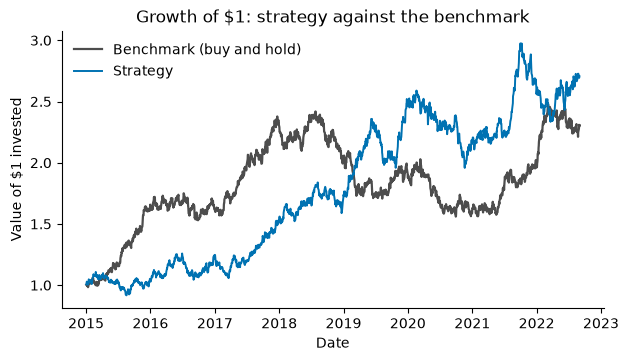

In [6]:
COLORS = ["#4D4D4D", "#0072B2", "#D55E00", "#009E73", "#CC79A7"]   # benchmark first (dark grey), then colour-blind-safe
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(bench.index, (1 + bench).cumprod(), color=COLORS[0], lw=1.6, label="Benchmark (buy and hold)")
ax.plot(strat.index, (1 + strat).cumprod(), color=COLORS[1], lw=1.4, label="Strategy")
ax.set_title("Growth of $1: strategy against the benchmark")
ax.set_xlabel("Date")
ax.set_ylabel("Value of $1 invested")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
save_figure(fig, "growth.pdf", "Growth of $1: strategy against the benchmark", "Date", "Value of $1 invested",
            ["Benchmark (buy and hold)", "Strategy"])


## Step 5. Numbers file for the report

**What:** writes `final_report/key_numbers.json`, a flat `{"MacroName": "value-as-printed-in-RESULT.md"}`
map (macro names letters only). `numbers_to_tex.py` turns it into LaTeX macros.
**Why:** the paper quotes only numbers that trace to saved outputs; `check_report.py` verifies each value
appears verbatim in RESULT.md or an `output/*.json`.
**Inputs:** `results`. **Outputs:** `final_report/key_numbers.json`.

In [7]:
key_numbers = {
    "NDays": f"{results['n_days']:,}",
    "ExcessAnnPct": f"{results['excess_ann'] * 100:.2f}",
    "TStat": f"{results['t_stat']:.2f}",
}
(FR / "key_numbers.json").write_text(json.dumps(key_numbers, indent=1), encoding="utf-8")
print(key_numbers)


{'NDays': '2,000', 'ExcessAnnPct': '2.07', 'TStat': '0.25'}


## Step 6. Verify the saved outputs (PASS / FAIL)

**What:** hashes every file in `output/` and compares it with the manifest checksums. For a finished
study the reference is `final_report/replication/MANIFEST.json` (`output_sha256`); while a study is still
being built, the first run records `output/CHECKSUMS.json` as the baseline and later runs compare with it.
**Why:** proves that Run All reproduced the saved results byte for byte (or tells you exactly which
files differ). A FAIL raises, so a headless run exits non-zero.
**Inputs:** `output/*`, the manifest. **Outputs:** the printed PASS / FAIL (and `CHECKSUMS.json` on the
first run).

In [8]:
######################### Verify #######################
manifest_path = FR / "replication" / "MANIFEST.json"
files = {"output/" + str(f.relative_to(OUT)).replace("\\", "/"): f for f in sorted(OUT.rglob("*"))
         if f.is_file() and "_cache" not in f.parts and f.name != "CHECKSUMS.json"}
current = {rel: sha256(f) for rel, f in files.items()}
if manifest_path.exists():
    reference, source = json.loads(manifest_path.read_text(encoding="utf-8"))["output_sha256"], "replication MANIFEST.json"
elif (OUT / "CHECKSUMS.json").exists():
    reference, source = json.loads((OUT / "CHECKSUMS.json").read_text(encoding="utf-8")), "output/CHECKSUMS.json"
else:
    (OUT / "CHECKSUMS.json").write_text(json.dumps(current, indent=1), encoding="utf-8")
    reference, source = current, "output/CHECKSUMS.json (baseline recorded on this first run)"
missing = [k for k in reference if k not in current]
differs = [k for k in reference if k in current and current[k] != reference[k]]
extra = [k for k in current if k not in reference]
print(f"reference: {source}")
print(f"outputs matching: {len(reference) - len(missing) - len(differs)}/{len(reference)}   missing {missing}   differs {differs}   not in reference {extra}")
VERIFY_OK = not missing and not differs
print(f"runtime {time.time() - T_START:.0f}s")
print("PASS" if VERIFY_OK else "FAIL")
assert VERIFY_OK, "saved outputs do not match the reference checksums (see lists above)"


reference: output/CHECKSUMS.json (baseline recorded on this first run)
outputs matching: 1/1   missing []   differs []   not in reference []
runtime 12s
PASS
